# **Curso: Modelos de Aprendizaje**

# **UNIDAD 2**



* Jesús Isaac Antonio Altamirano
* 22111389

Montamos en Google Drive primeramente

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [7]:
import os
DIR = "/content/drive/MyDrive/Inteligencia Artificial/Unidad 2"
os.chdir(DIR)

# Verificamos que el archivo data.csv aparezca en la lista
print("Directorio de trabajo:", os.getcwd())
print("Archivos:", os.listdir())

Directorio de trabajo: /content/drive/MyDrive/Inteligencia Artificial/Unidad 2
Archivos: ['bigMartSales.csv', 'EjemploModeloRegresionLineal_mejorado.ipynb', 'MRL_JIAA_22111389.ipynb', 'Práctica2_U2.ipynb']


Importamos las librerías que vamos a estar utilizando

In [8]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Librerías para el pre-procesamiento e ing de características
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder,StandardScaler, OrdinalEncoder,FunctionTransformer

# Librerías para la canalización
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import make_pipeline

# Librerías para la regresión
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, mean_squared_error, r2_score, confusion_matrix, precision_score,recall_score,accuracy_score
from sklearn.decomposition import PCA

from sklearn.preprocessing import PolynomialFeatures

**Explica brevemente el uso de las librerías del segmento de código anterior, haciendo uso de la siguiente tabla**

---

## **<font color="#895cf9">Explica brevemente el uso de las librerias del segmento de codigo anterior, haciendo uso de la siguiente tabla</font>**

| Library | Explanation |
|----------|--------------|
| **import numpy as np** | Manipulación de datos mediante operaciones matemáticas y arreglos (arrays) numéricos de N dimensiones. Aquí se usa, por ejemplo, para seleccionar columnas numéricas (`np.number`) y aplicar la raíz cuadrada (`np.sqrt`). |
| **import pandas as pd** | Lectura, manipulación y análisis de datos tabulares mediante *DataFrames*: cargar el CSV, seleccionar o eliminar columnas, obtener estadísticas con `describe()`, contar valores faltantes, etc. |
| **import matplotlib.pyplot as plt** | Biblioteca base para graficar: histogramas, box plots y figuras con varias subgráficas (`plt.subplots`). |
| **import seaborn as sns** | Visualización estadística construida sobre matplotlib; aquí se usa `countplot`, `heatmap` y `pairplot`. |
| **from sklearn.impute import SimpleImputer** | Rellena valores faltantes (NaN) con la media, mediana, moda o un valor constante. |
| **from sklearn.preprocessing import MinMaxScaler** | Escala cada variable al intervalo [0, 1] usando el mínimo y el máximo. |
| **from sklearn.preprocessing import StandardScaler** | Estandariza las variables para que tengan media 0 y desviación estándar 1. |
| **from sklearn.preprocessing import OneHotEncoder** | Convierte variables categóricas en columnas binarias (0/1), una por cada categoría. |
| **from sklearn.preprocessing import OrdinalEncoder** | Convierte categorías en números enteros que respetan un orden. |
| **from sklearn.preprocessing import FunctionTransformer** | Convierte una función cualquiera (por ejemplo `np.sqrt`) en un transformador compatible con `ColumnTransformer` y los pipelines. |
| **from sklearn.compose import ColumnTransformer, make_column_selector** | `ColumnTransformer` aplica transformaciones distintas a diferentes columnas; `make_column_selector` selecciona columnas por tipo de dato o por nombre. |
| **from sklearn.pipeline import make_pipeline** | Encadena pasos (preprocesamiento + modelo) en un solo objeto con `fit` y `predict`. Está importado dos veces en el código, lo cual es redundante pero no causa error. |
| **from sklearn.linear_model import LinearRegression** | Modelo de regresión lineal para predecir variables numéricas continuas. En esta práctica no se utiliza (se importó de la práctica anterior). |
| **from sklearn.linear_model import LogisticRegression** | Modelo de clasificación que estima la probabilidad de pertenecer a una clase mediante la función sigmoide. Es el modelo principal de esta práctica. |
| **from sklearn.metrics import mean_squared_error, r2_score** | Métricas de regresión: error cuadrático medio y coeficiente de determinación R². No se usan en esta práctica (`mean_squared_error` está importado dos veces). |
| **from sklearn.metrics import confusion_matrix, precision_score, recall_score, accuracy_score** | Métricas de clasificación: matriz de confusión, precisión, sensibilidad (*recall*) y exactitud (*accuracy*). Sirven para evaluar el modelo en el conjunto de prueba. |
| **from sklearn.decomposition import PCA** | Análisis de Componentes Principales: reduce la dimensionalidad creando componentes no correlacionados; es la alternativa a eliminar variables para tratar la multicolinealidad. |
| **from sklearn.preprocessing import PolynomialFeatures** | Genera términos polinomiales y de interacción entre variables para modelar relaciones no lineales. No se usa en esta práctica. |

---

In [14]:
#lectura del .csv con pandas
data_df = pd.read_csv('/content/drive/MyDrive/Inteligencia Artificial/Unidad 2/data.csv')

# Algunas versiones del dataset traen una columna vacía llamada "Unnamed: 32"; si existe, se elimina
data_df = data_df.loc[:, ~data_df.columns.str.contains('^Unnamed')]

data_df.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


# **Parte 1.- EDA**
Haz que el ID sea el índice del dataframe y efectúa una exploración inicial de los datos a través de:**texto en negrita**

In [15]:
#utilice funcion .set_index()
#Guarde los cambios con inplace=True

#-----------------------------------------------------
data_df.set_index('id', inplace=True)
#-----------------------------------------------------

#-----------------------------------------------------
print('Dimensiones (filas, columnas):', data_df.shape)
#-----------------------------------------------------

Dimensiones (filas, columnas): (569, 31)


In [31]:
data_df

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
id,,,,,,,,,,,,,,,,,,,,,
842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820


## 1A) Estadísticas descriptivas para todas las variables del dataframe

In [16]:
#.describe para variables Numericas
#-----------------------------------------------------
data_df.describe()
#-----------------------------------------------------

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [17]:
#.describe() para variable categoricas
#-----------------------------------------------------
data_df.describe(include='object')
#-----------------------------------------------------

,diagnosis
count,569
unique,2
top,B
freq,357


## 1B) Valores únicos por variable para identificar posibles variables categóricas

In [18]:
# Cantidad de valores únicos por variable: las que tienen muy pocos valores únicos
# (en este caso 'diagnosis', con 2) son candidatas a ser categóricas
data_df.nunique()

,0
diagnosis,2
radius_mean,456
texture_mean,479
perimeter_mean,522
area_mean,539
smoothness_mean,474
compactness_mean,537
concavity_mean,537
concave points_mean,542
symmetry_mean,432


In [19]:
# Se hace una lista de variables numéricas y otra de categóricas.

#-----------------------------------------------------
num_cols = data_df.select_dtypes(include=np.number).columns.tolist() #para variables numericas
cat_cols = data_df.select_dtypes(exclude=np.number).columns.tolist() #para variables Categoricas
#-----------------------------------------------------

print('Variables numéricas (', len(num_cols), '):', num_cols)
print()
print('Variables categóricas (', len(cat_cols), '):', cat_cols)

Variables numéricas ( 30 ): ['radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst']

Variables categóricas ( 1 ): ['diagnosis']


In [20]:
# Recuento de cada categoría única en las variables categóricas
for col in cat_cols:
  print(data_df[col].value_counts())
  print()

diagnosis
B    357
M    212
Name: count, dtype: int64



In [21]:
# Recuento de cada categoría única en las variables categóricas (en porcentaje)
for col in cat_cols:
  print((data_df[col].value_counts(normalize=True)*100).round(2))
  print()

diagnosis
B    62.74
M    37.26
Name: proportion, dtype: float64



## 1C) Búsqueda de valores faltantes

In [22]:
#Explica cada linea de codigo

# Imprime un encabezado para el listado de resultados
print('Número valores faltantes: ')

# Recorre, una por una, todas las columnas del dataframe (col toma el nombre de cada columna)
for col in data_df.columns:

  # data_df[col].isna() devuelve True donde hay un valor faltante (NaN) y False donde no;
  # sum() suma los True, es decir, cuenta cuántos valores faltantes tiene la columna
  valor=sum(data_df[col].isna())

  # isna().mean() calcula la proporción de True (faltantes) entre el total de filas;
  # al multiplicar por 100 se obtiene el porcentaje de faltantes de la columna
  porcentaje=data_df[col].isna().mean()*100

  # Imprime: nombre de la columna : cantidad de faltantes : porcentaje de faltantes
  print('{}:{}: porcentaje :{}'.format(col,valor,porcentaje))

Número valores faltantes: 
diagnosis:0: porcentaje :0.0
radius_mean:0: porcentaje :0.0
texture_mean:0: porcentaje :0.0
perimeter_mean:0: porcentaje :0.0
area_mean:0: porcentaje :0.0
smoothness_mean:0: porcentaje :0.0
compactness_mean:0: porcentaje :0.0
concavity_mean:0: porcentaje :0.0
concave points_mean:0: porcentaje :0.0
symmetry_mean:0: porcentaje :0.0
fractal_dimension_mean:0: porcentaje :0.0
radius_se:0: porcentaje :0.0
texture_se:0: porcentaje :0.0
perimeter_se:0: porcentaje :0.0
area_se:0: porcentaje :0.0
smoothness_se:0: porcentaje :0.0
compactness_se:0: porcentaje :0.0
concavity_se:0: porcentaje :0.0
concave points_se:0: porcentaje :0.0
symmetry_se:0: porcentaje :0.0
fractal_dimension_se:0: porcentaje :0.0
radius_worst:0: porcentaje :0.0
texture_worst:0: porcentaje :0.0
perimeter_worst:0: porcentaje :0.0
area_worst:0: porcentaje :0.0
smoothness_worst:0: porcentaje :0.0
compactness_worst:0: porcentaje :0.0
concavity_worst:0: porcentaje :0.0
concave points_worst:0: porcentaje :

**Interpretación.** Todas las columnas muestran 0 valores faltantes (0 %), por lo que no es necesario imputar datos (no se requiere `SimpleImputer`).

1d) Diagrama de barras para determinar la frecuencia de los diagnósticos (cantidad de observaciones con resultado benigno y maligno)

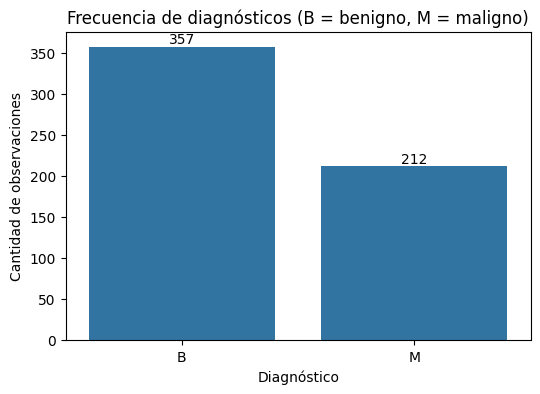

In [23]:
#utilice sns.countplot()
#-----------------------------------------------------
plt.figure(figsize=(6,4))
ax = sns.countplot(x='diagnosis', data=data_df, order=['B','M'])
ax.bar_label(ax.containers[0])   # muestra la cantidad sobre cada barra
plt.title('Frecuencia de diagnósticos (B = benigno, M = maligno)')
plt.xlabel('Diagnóstico')
plt.ylabel('Cantidad de observaciones')
plt.show()
#-----------------------------------------------------

**Interpretación.** La gráfica muestra que el conjunto está **desbalanceado de forma moderada**: hay 357 diagnósticos benignos (`B`, ≈ 62.7 %) frente a 212 malignos (`M`, ≈ 37.3 %). No es un desbalance extremo, pero hay que tenerlo presente: por eso no basta con mirar el *accuracy*; también hay que revisar el *recall* y la *precision* de la clase maligna (`M`), que es la clase positiva y la más importante de detectar.

2. Como hay tres valores relacionados con la misma característica (`mean`, `se` y `worst`) es muy probable que exista multicolinealidad en el conjunto.

La multicolinealidad en regresión es una condición que ocurre cuando algunas variables predictoras están fuertemente correlacionadas entre sí, de tal manera que si se incluyen simultáneamente en un modelo, impiden explicar de manera correcta el efecto que cada una tiene sobre la variable respuesta. Existen muchas formas de analizar si hay colinealidad en los modelos, una de ellas es el alto coeficiente de correlación entre variables.

Para observar este efecto, elabora un mapa de calor que cuantifique la correlación de las variables numéricas en el dataframe.

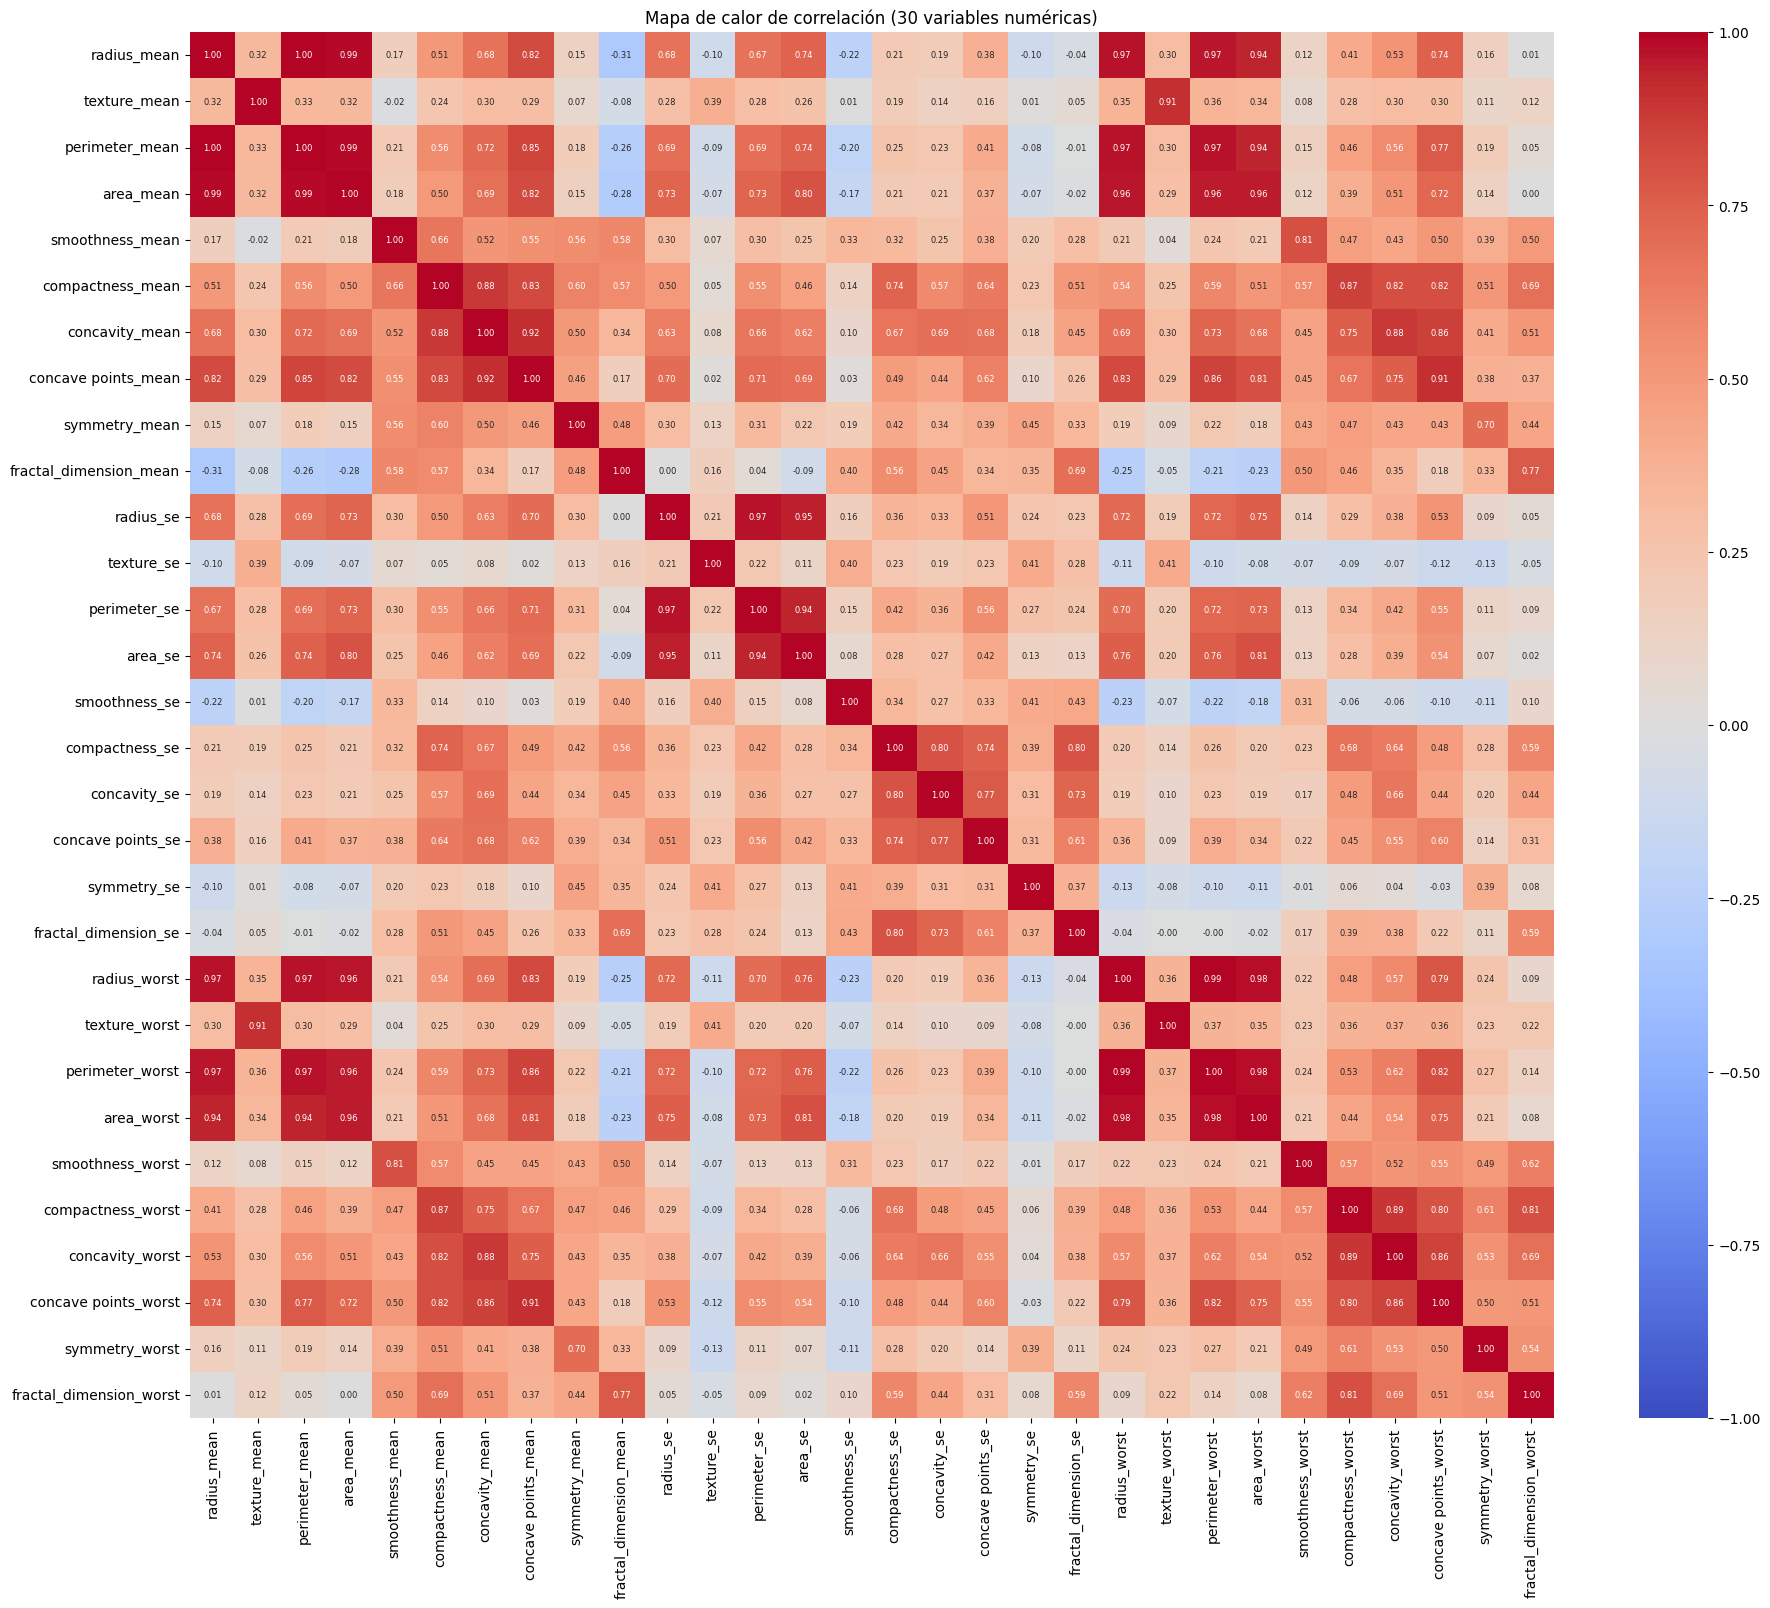

In [24]:
numeric_df = data_df.select_dtypes(include=[float, int])

#-----------------------------------------------------
plt.figure(figsize=(22,18))
sns.heatmap(numeric_df.corr(), annot=True, fmt='.2f', annot_kws={'size':6}, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Mapa de calor de correlación (30 variables numéricas)')
plt.show()
#-----------------------------------------------------

Si te fijas en los valores de correlación entre las variables `_mean` y `_worst` es evidente la multicolinearidad.

Por ejemplo, la columna `radius_mean` tiene una correlación de 0.97 con la columna `radius_worst`. Esto es algo inevitable, porque las columnas "peores" son esencialmente solo un subconjunto de las columnas "medias".

Para solucionar el problema numérico de la multicolinealidad, tradicionalmente se recurre a eliminar variables o efectuar análisis de componentes principales (PCA) con las `X`’s y usar los componentes como variables independientes en un modelo final.

Conduciremos esta actividad en esos dos sentidos.

**Interpretación.** En el mapa de calor se ven bloques de color muy intenso (correlaciones cercanas a 1). Cada variable `_mean` está fuertemente correlacionada con su versión `_worst`: entre ≈ 0.70 (`symmetry`) y ≈ 0.97 (`radius`, `perimeter`). Además, `radius`, `perimeter` y `area` están casi perfectamente correlacionadas entre sí (por ejemplo, `radius_mean` con `perimeter_mean` ≈ 0.998 y con `area_mean` ≈ 0.987), y también son altas las correlaciones entre `compactness`, `concavity` y `concave points`. Esto confirma que existe **multicolinealidad**: varias columnas aportan casi la misma información, lo que vuelve inestables los coeficientes de la regresión logística y dificulta interpretar el efecto individual de cada predictor.

# **Parte 2**. Modelo con eliminación de variables altamente correlacionadas

Elimina las variables altamente correlacionadas:

3a) Ahora que sabes que las variables `_mean` y `_worst` tienen correlación alta, hay que quitar del dataframe un conjunto. Borra las columnas `_worst`.

In [25]:
#-----------------------------------------------------
#Elimine TODAS las columnas _worst
columnas_worst = [c for c in data_df.columns if c.endswith('_worst')]
print('Columnas _worst a eliminar (', len(columnas_worst), '):', columnas_worst)
#-----------------------------------------------------

#para borrar las columnas _worst
new_data_df = data_df.drop(columns=columnas_worst)

#-----------------------------------------------------
#Convierte new_data_df en Dataframe usando .DataFrame() de la libreria de pandas
new_data_df = pd.DataFrame(new_data_df)
#-----------------------------------------------------

new_data_df

Columnas _worst a eliminar ( 10 ): ['radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst']


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se
id,,,,,,,,,,,,,,,,,,,,,
842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,...,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193
842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,...,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532
84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,...,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571
84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,...,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208
84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,...,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,...,1.1760,1.2560,7.673,158.70,0.010300,0.02891,0.05198,0.02454,0.01114,0.004239
926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,...,0.7655,2.4630,5.203,99.04,0.005769,0.02423,0.03950,0.01678,0.01898,0.002498
926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,...,0.4564,1.0750,3.425,48.55,0.005903,0.03731,0.04730,0.01557,0.01318,0.003892


En las graficas de dispersion, los patrones lineales en los diagramas de dispersion se refieren a la relacion entre dos variables que sigue una tendencia aproximadamente en linea recta, ya sea en direccion ascendente o descentende

* **Patron lineal positivo**: Si la linea se inclina hacia arriba (de izquierda a derecha), indica que hay una relacion directa entre las variables: cuando la variable aumenta, la otra tambien lo hace, es decir, CORRELACION POSITIVA

* **Patron lineal negativo**: si la linea se incluna hacia abajo (de izquierda a derecha), indica quue cuando una variable aumenta, la otra disminuye, es decir, CORRELACION NEGATIVA

* **Patron lineal perfecto**, si los puntos siguen una linea recta perfecta, la relacion entre las variables es exactamente lineal, sin desviaciones.


3b. Entre las variables `_mean`, identifica patrones lineales con diagramas de dispersión usando `sns.pairplot(...)`:

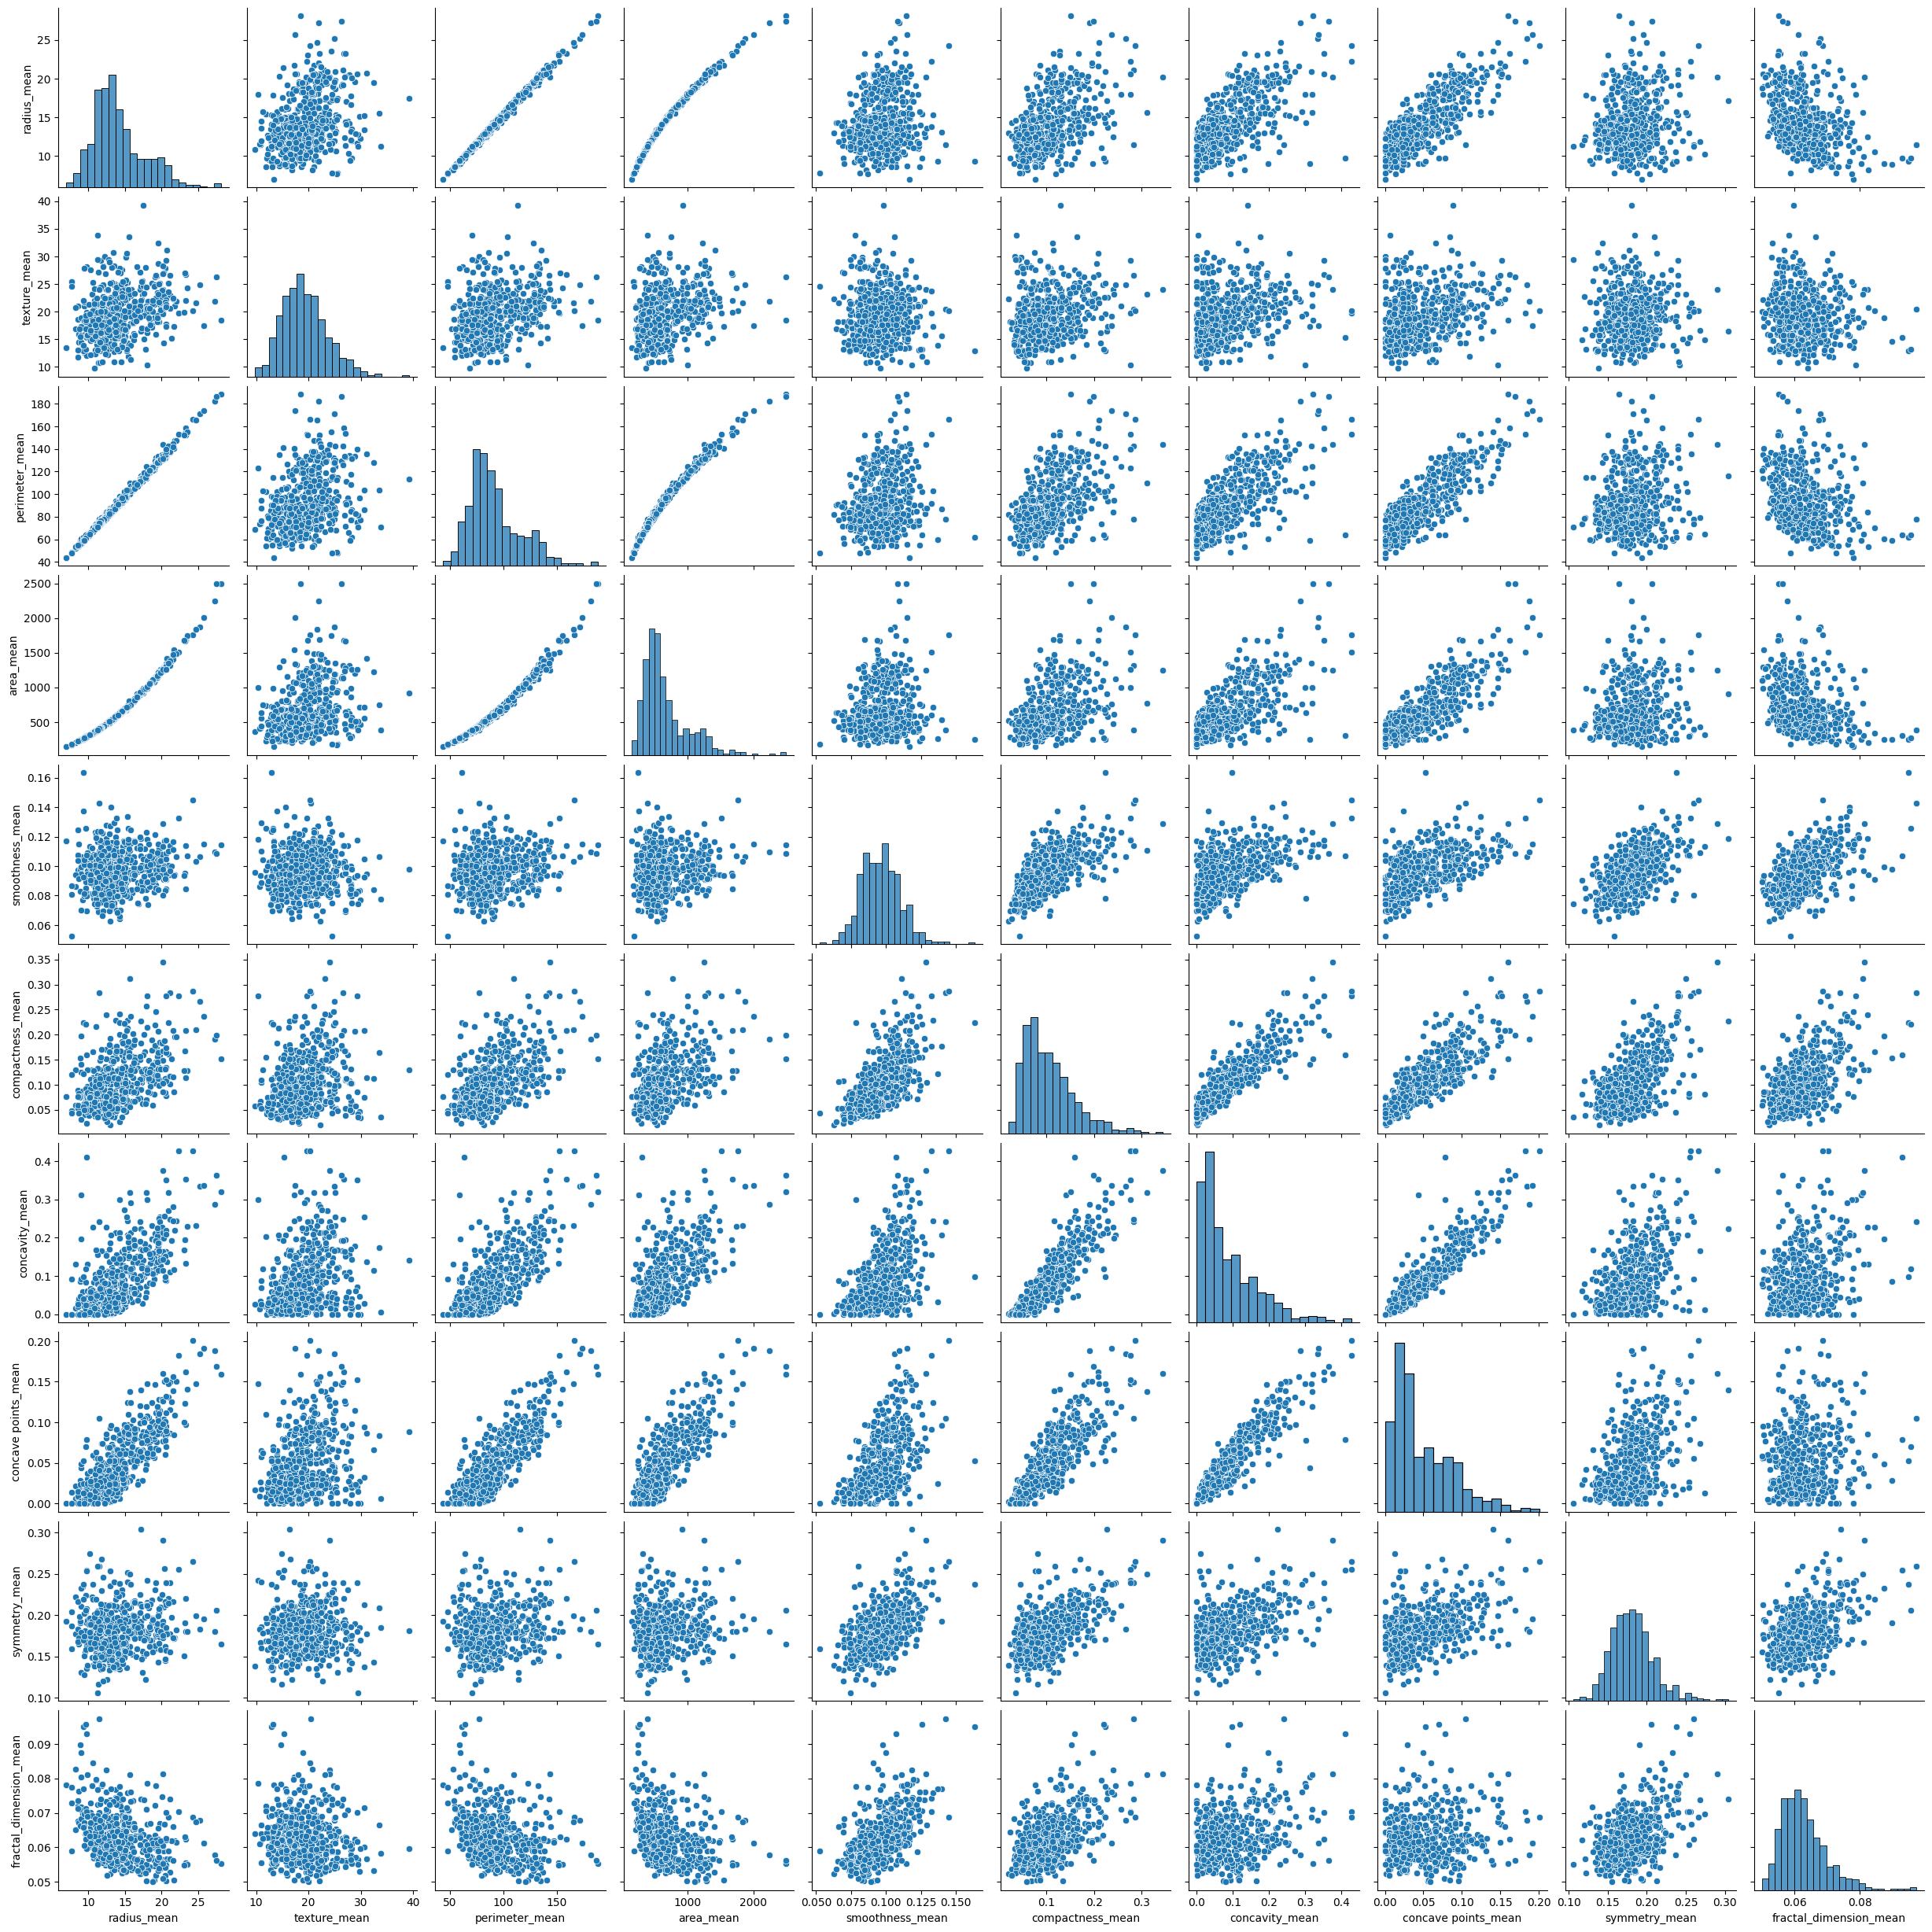

In [26]:
#-----------------------------------------------------
# (En el enunciado el dataframe se llama nuevo_df; aquí corresponde a new_data_df)
sns.pairplot(data=new_data_df[['radius_mean',
    'texture_mean',
    'perimeter_mean',
    'area_mean',
    'smoothness_mean',
    'compactness_mean',
    'concavity_mean',
    'concave points_mean',
    'symmetry_mean',
    'fractal_dimension_mean']])
plt.show()
#-----------------------------------------------------

De la matriz podrás observar relaciones lineales bastante evidentes entre:

*   `radius_mean`, `perimeter_mean` y `area_mean`
*   `compactness_mean`, `concavity_mean`, `concave_points_mean`

Sabemos que el perímetro y el área de un círculo, se calculan a partir del radio. Entonces, la relación entre las primeras tres variables es muy clara para nosotros.

3c) Elabora otro mapa de calor confirmar con los valores de correlación.

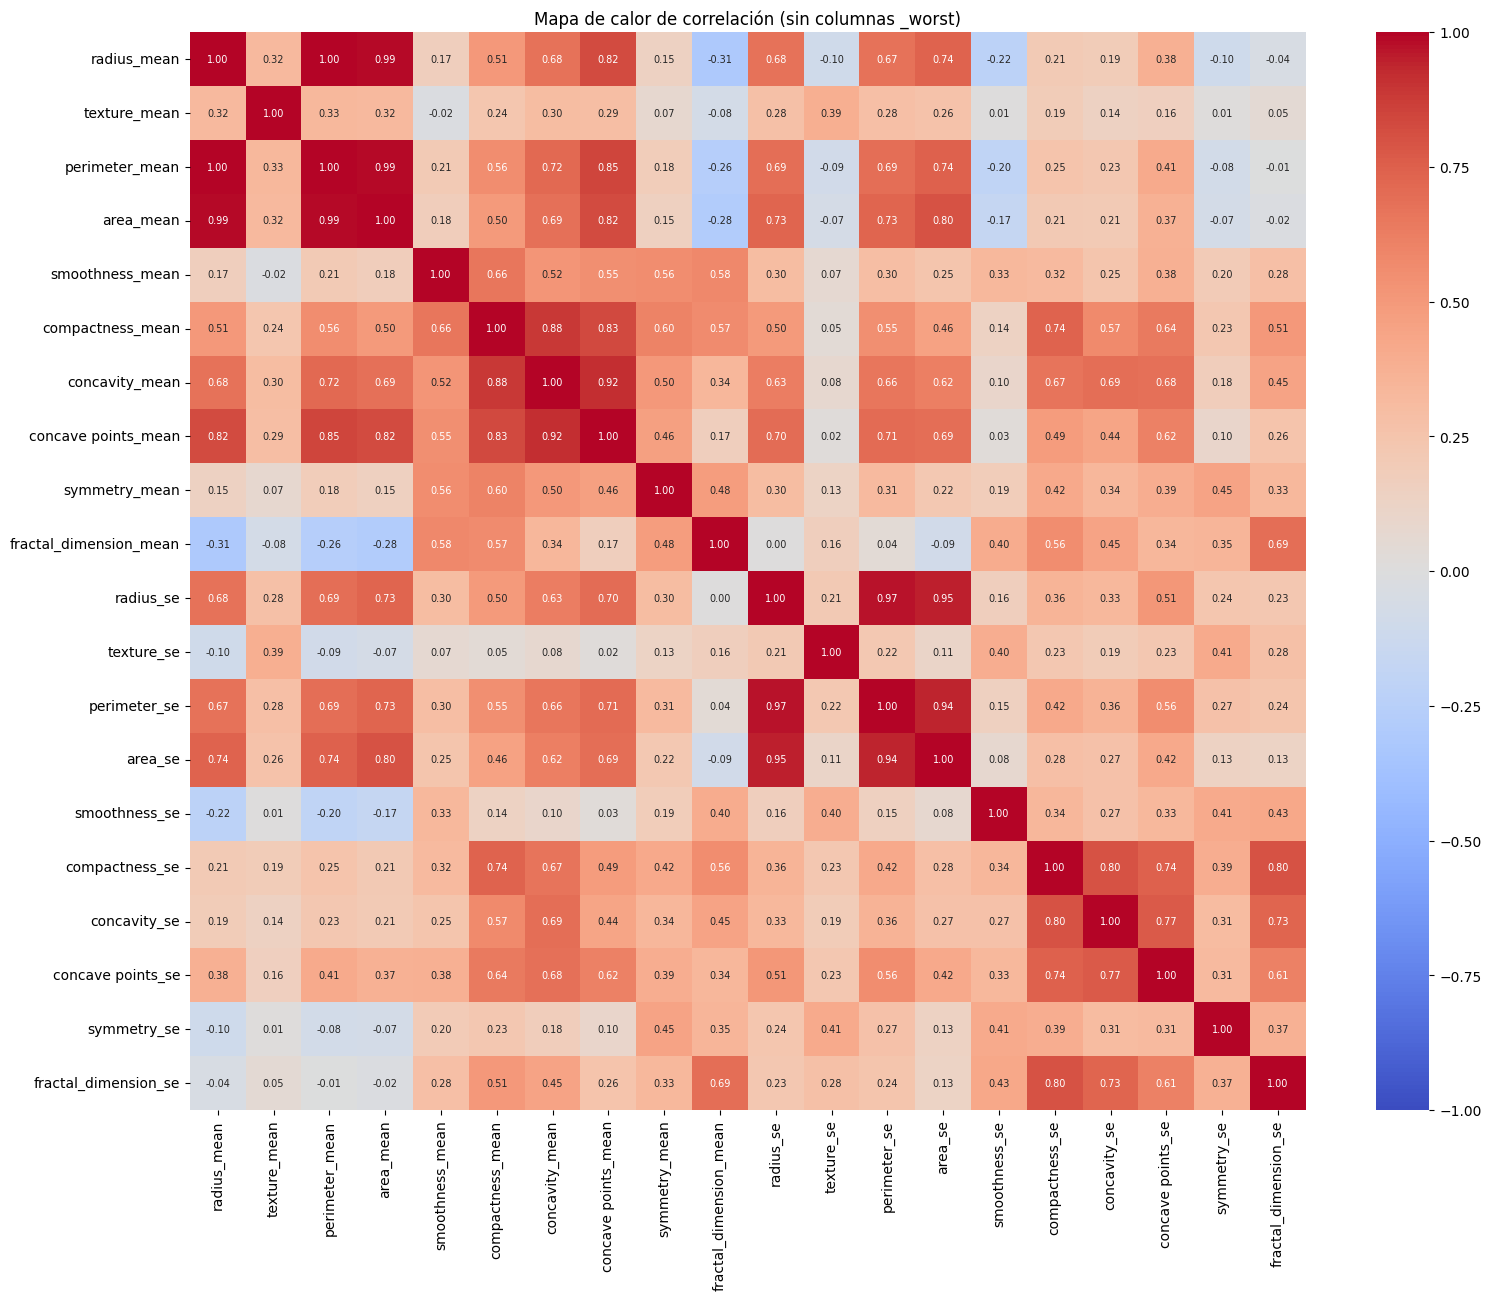

In [27]:
#-----------------------------------------------------
numeric_df2 = new_data_df.select_dtypes(include=[float, int])

plt.figure(figsize=(18,14))
sns.heatmap(numeric_df2.corr(), annot=True, fmt='.2f', annot_kws={'size':7}, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Mapa de calor de correlación (sin columnas _worst)')
plt.show()
#-----------------------------------------------------

**Interpretación.** Con las columnas `_worst` fuera, el mapa de calor sigue mostrando correlaciones muy altas entre `radius_mean`, `perimeter_mean` y `area_mean` (≈ 0.987 – 0.998), y entre `compactness_mean`, `concavity_mean` y `concave points_mean` (≈ 0.83 – 0.92). Lo mismo ocurre en las variables `_se`: `radius_se` con `perimeter_se` ≈ 0.97 y con `area_se` ≈ 0.95, y correlaciones de ≈ 0.74 – 0.80 entre `compactness_se`, `concavity_se` y `concave points_se`. Por eso se conserva **una sola variable de cada trío** (`radius` y `compactness`) y se eliminan las demás, tanto en `_mean` como en `_se`: `perimeter`, `area`, `concavity` y `concave points`.

3d) Después de observar los valores, nos quedaremos con sólo una variable de cada trío: `radius_mean` y `compactness_mean`. Elimina las restantes, no sólo del conjunto `_mean`, sino también de `_se`.

In [28]:
#-----------------------------------------------------
#escriba TODAS las columnas que seran eliminadas
columnas_a_eliminar=['perimeter_mean','area_mean','concavity_mean','concave points_mean',
                     'perimeter_se','area_se','concavity_se','concave points_se']
#-----------------------------------------------------

#-----------------------------------------------------
#Convierte new_data_df en Dataframe usando .DataFrame() de la libreria de pandas
new_data_df = pd.DataFrame(new_data_df.drop(columns=columnas_a_eliminar))
new_data_df
#-----------------------------------------------------

,diagnosis,radius_mean,texture_mean,smoothness_mean,compactness_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,smoothness_se,compactness_se,symmetry_se,fractal_dimension_se
id,,,,,,,,,,,,,
842302,M,17.99,10.38,0.11840,0.27760,0.2419,0.07871,1.0950,0.9053,0.006399,0.04904,0.03003,0.006193
842517,M,20.57,17.77,0.08474,0.07864,0.1812,0.05667,0.5435,0.7339,0.005225,0.01308,0.01389,0.003532
84300903,M,19.69,21.25,0.10960,0.15990,0.2069,0.05999,0.7456,0.7869,0.006150,0.04006,0.02250,0.004571
84348301,M,11.42,20.38,0.14250,0.28390,0.2597,0.09744,0.4956,1.1560,0.009110,0.07458,0.05963,0.009208
84358402,M,20.29,14.34,0.10030,0.13280,0.1809,0.05883,0.7572,0.7813,0.011490,0.02461,0.01756,0.005115
...,...,...,...,...,...,...,...,...,...,...,...,...,...
926424,M,21.56,22.39,0.11100,0.11590,0.1726,0.05623,1.1760,1.2560,0.010300,0.02891,0.01114,0.004239
926682,M,20.13,28.25,0.09780,0.10340,0.1752,0.05533,0.7655,2.4630,0.005769,0.02423,0.01898,0.002498
926954,M,16.60,28.08,0.08455,0.10230,0.1590,0.05648,0.4564,1.0750,0.005903,0.03731,0.01318,0.003892


Observa la distribución de las variables resultantes (deben ser 12, sin contar la columna de indice):

In [29]:
# Comprobación: deben quedar 12 variables numéricas (más 'diagnosis')
print('Variables numéricas restantes:', len(new_data_df.select_dtypes(include=np.number).columns))
print(new_data_df.columns.tolist())

Variables numéricas restantes: 12
['diagnosis', 'radius_mean', 'texture_mean', 'smoothness_mean', 'compactness_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'smoothness_se', 'compactness_se', 'symmetry_se', 'fractal_dimension_se']


4a) Utilizando histogramas. Guarda en una variable (`skew_cols`) las que tengan marcado sesgo positivo. Para dar seguridad a tu selección, elige aquellas cuyo resultado de aplicar la función `skew()` sea mayor a 1.

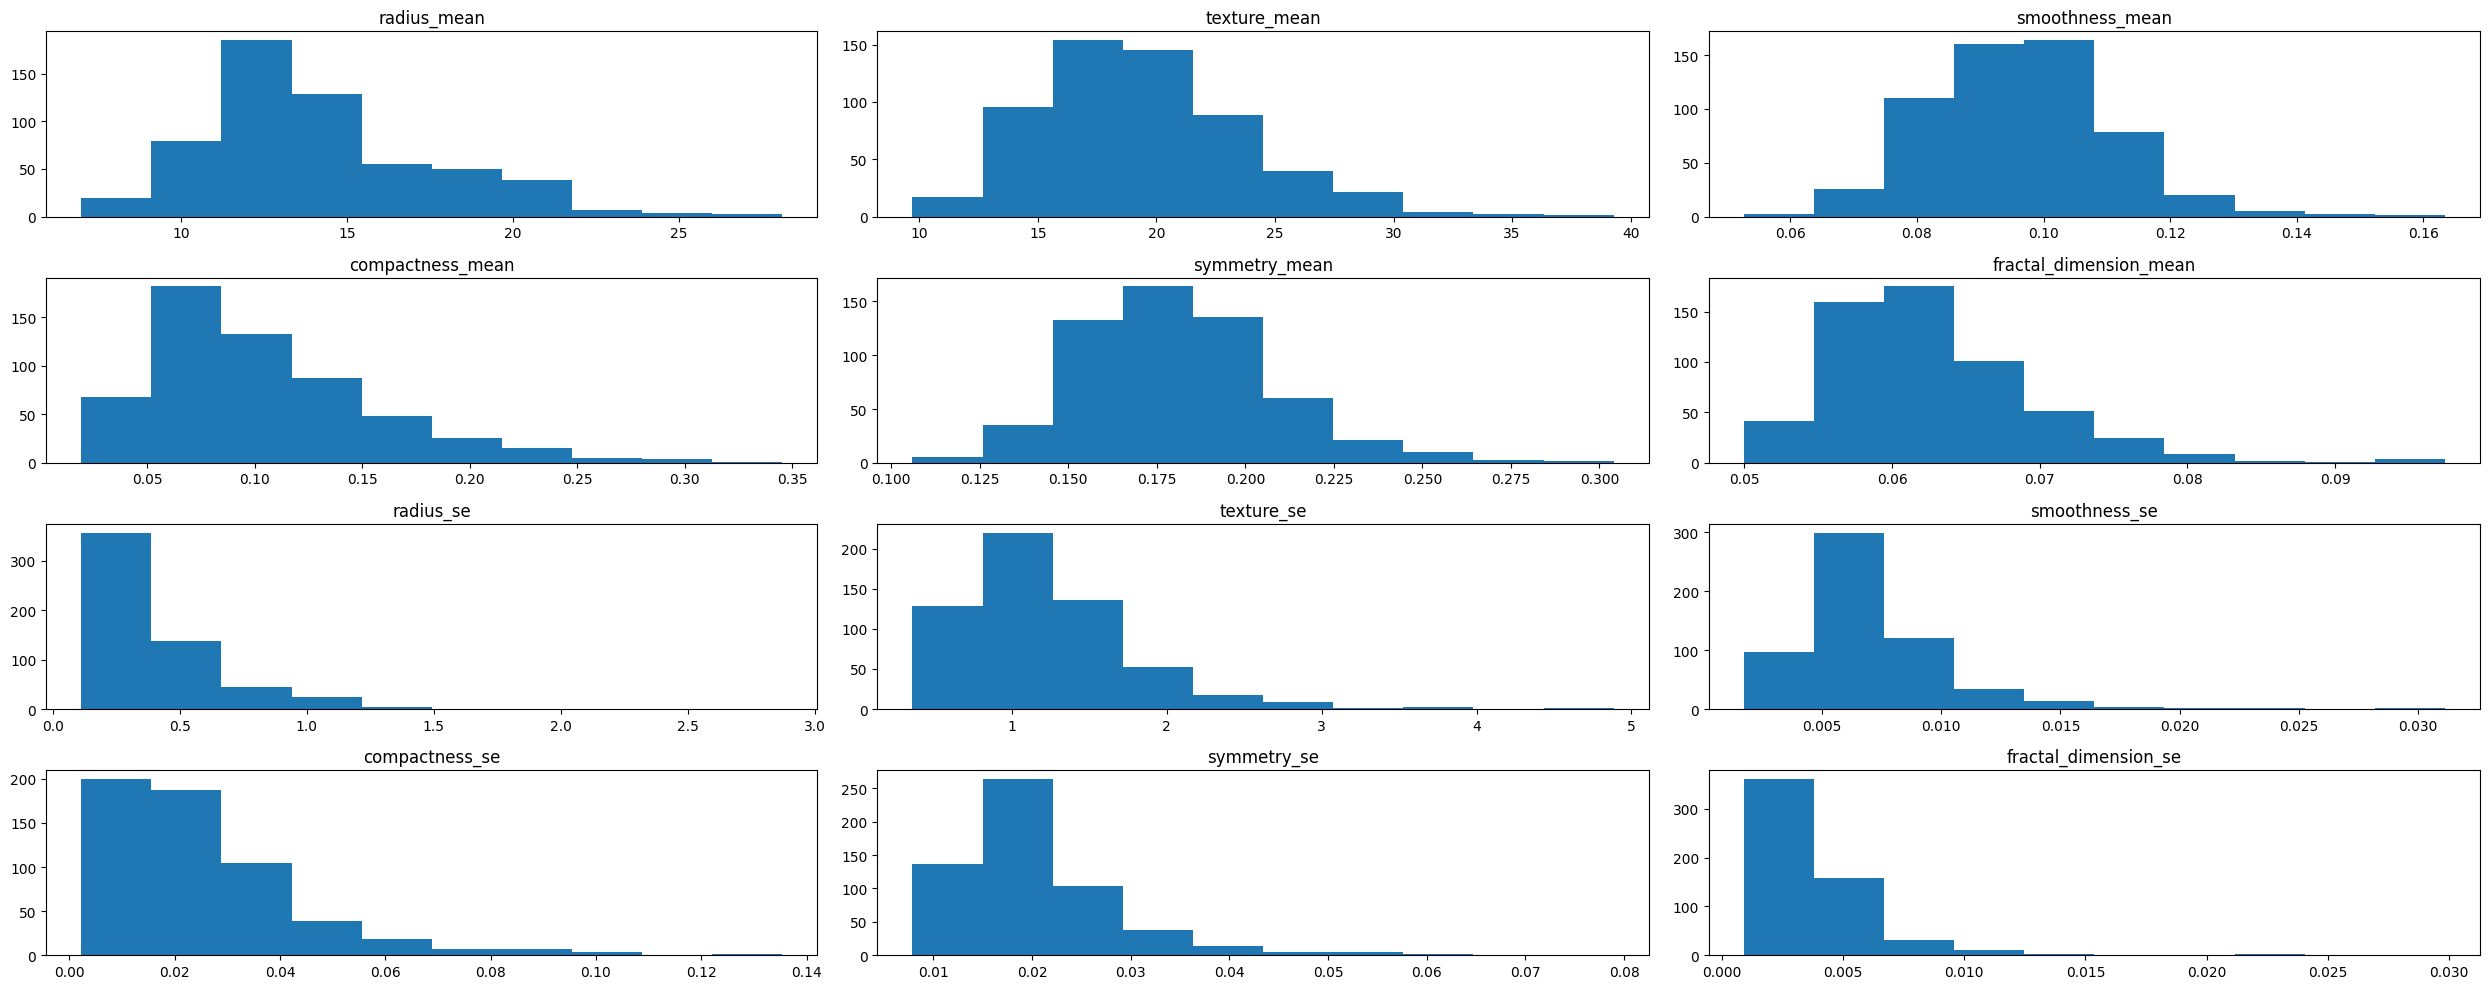

In [30]:
#EXPLICA CADA LINEA DE CODIGO

# Crea un DataFrame vacío donde se irán guardando las columnas con sesgo positivo
skew_cols_df=pd.DataFrame()

# Crea una figura con una cuadrícula de subgráficas de 4 filas x 3 columnas (12 gráficas);
# figsize=(25,10): 25 es el ancho y 10 la altura de la figura
fig, axes =plt.subplots(4,3, figsize=(25,10)) #25 es el ancho, 10 altura   ---- 4,3 significa que seran  4 filas y 3 columnas

# axes es una matriz de 4x3; ravel() la aplana en una lista de 12 ejes para recorrerla fácilmente
axes = axes.ravel()

# Lista con los nombres de las columnas numéricas del dataframe ya depurado (12 variables)
num_cols = new_data_df.select_dtypes(include=np.number).columns.tolist()

# zip empareja cada columna numérica con un eje (una subgráfica)
for col, ax in zip (num_cols, axes):
  # Dibuja el histograma de la variable en su subgráfica
  ax.hist(new_data_df[col])
  # Pone como título el nombre de la variable y quita la etiqueta del eje x
  ax.set(title = f'{col}', xlabel=None)
  # skew() mide la asimetría de la distribución; si es mayor a 1 hay sesgo positivo marcado
  # (cola larga a la derecha) y la columna se guarda en skew_cols_df
  if new_data_df[col].skew()>1 : skew_cols_df[col] =new_data_df[col]

# Guarda en skew_cols solo los nombres de las columnas con sesgo positivo
skew_cols = skew_cols_df.columns.values

plt.tight_layout()
plt.show()

In [32]:
skew_cols

array(['compactness_mean', 'fractal_dimension_mean', 'radius_se',
       'texture_se', 'smoothness_se', 'compactness_se', 'symmetry_se',
       'fractal_dimension_se'], dtype=object)

In [33]:
# Valor de skew() de cada variable, para respaldar la selección
new_data_df[num_cols].skew().sort_values(ascending=False)

,0
fractal_dimension_se,3.923969
radius_se,3.088612
smoothness_se,2.314450
symmetry_se,2.195133
compactness_se,1.902221
texture_se,1.646444
fractal_dimension_mean,1.304489
compactness_mean,1.190123
radius_mean,0.942380
symmetry_mean,0.725609


4b) Dibujando box plots de todas las variables. Guarda en una variable (`scale_cols`) aquellas que no se encuentren en el intervalo [0,1]

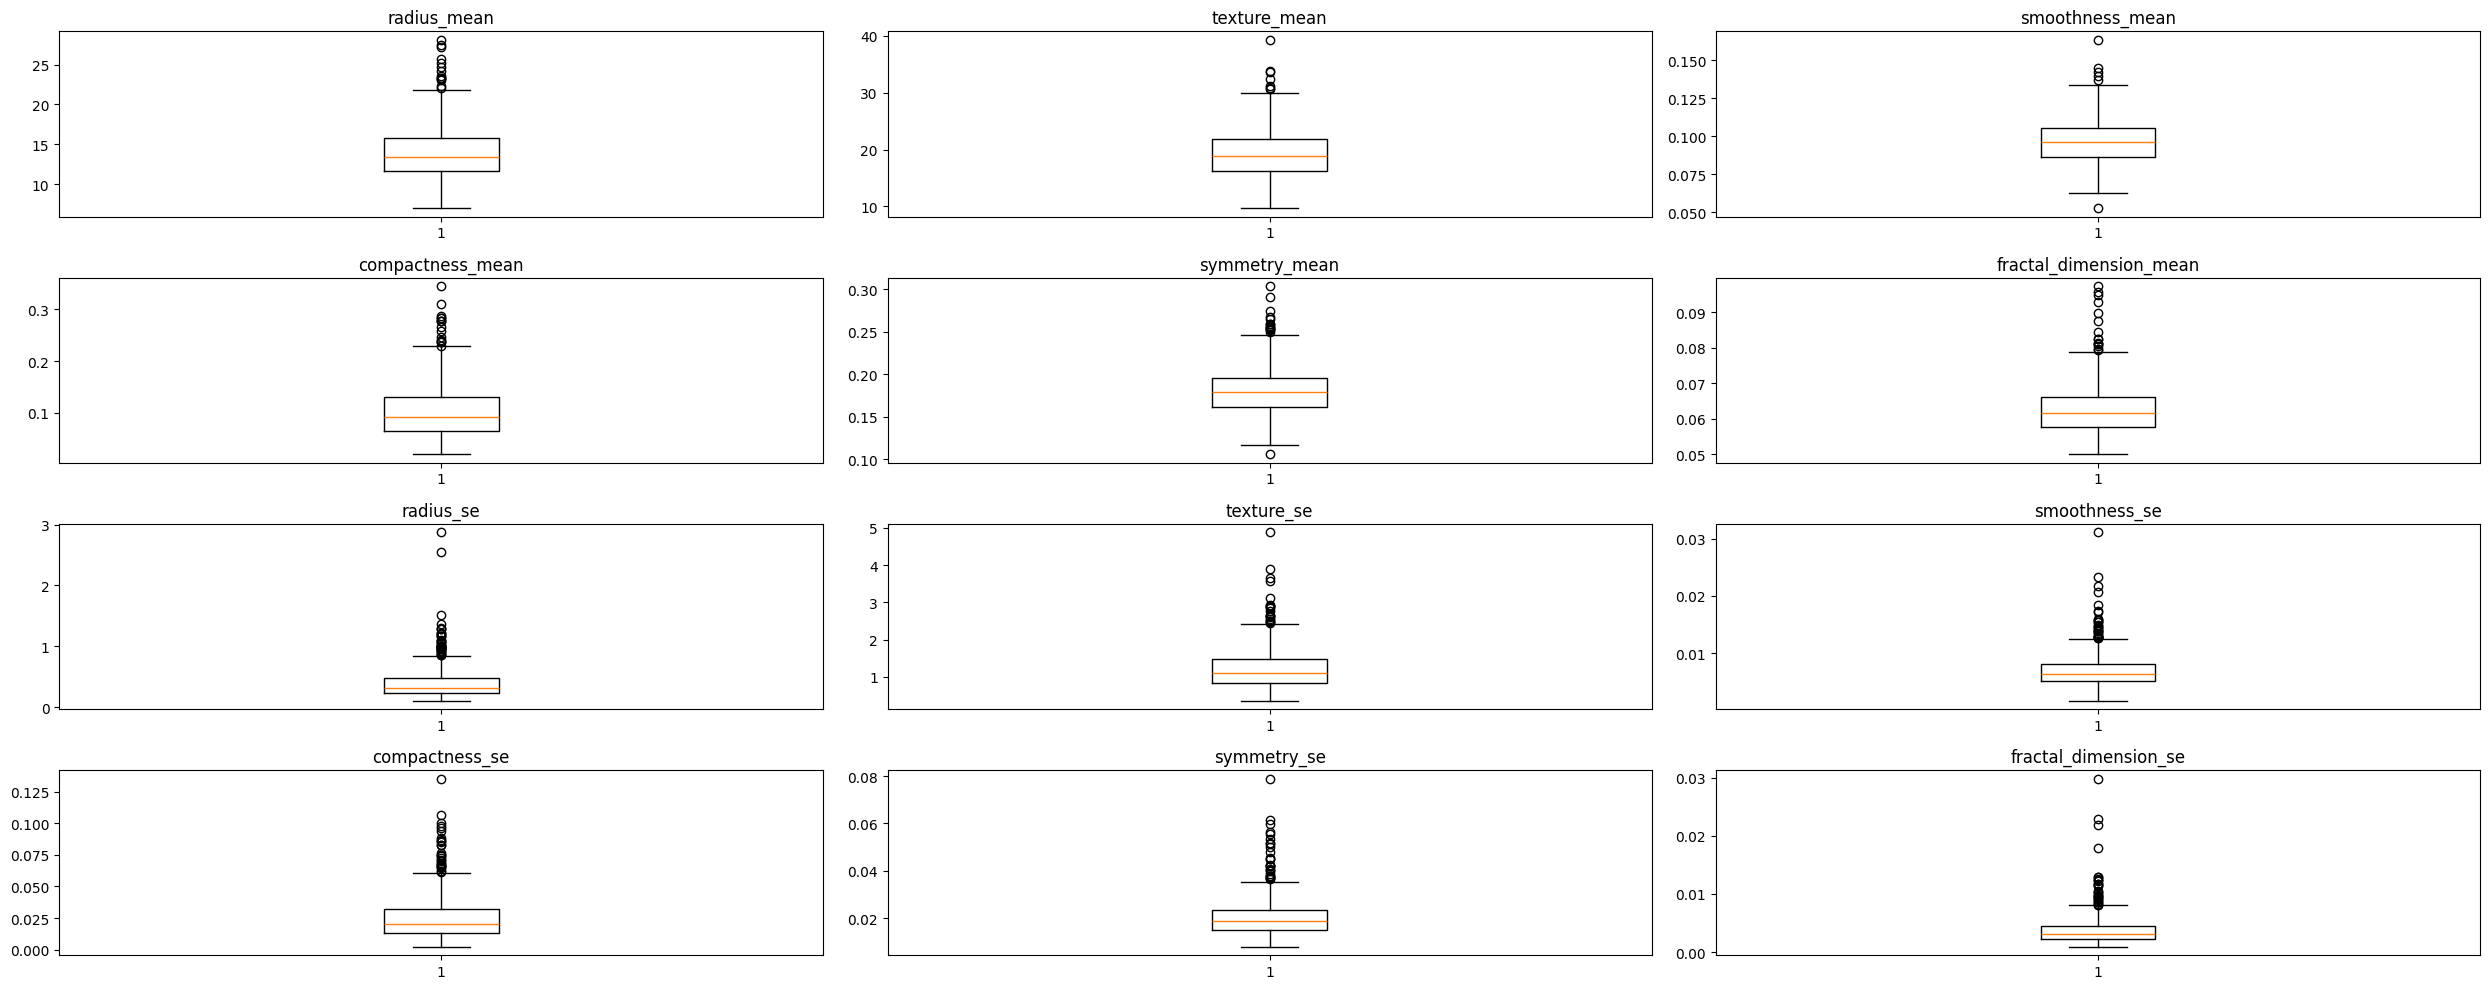

In [34]:
scale_cols_df=pd.DataFrame()
fig, axes = plt.subplots(4,3, figsize=(25,10))
axes = axes.ravel()

#-----------------------------------------------------
for col, ax in zip(new_data_df[num_cols], axes):

  ax.boxplot(new_data_df[col]) #COMPLETA LINEA DE CODIGO
  ax.set(title = f'{col}')

  #COMPLETA EL IF
  # Una variable NO está en el intervalo [0,1] si su máximo es mayor a 1 o su mínimo es menor a 0
  if new_data_df[col].max() > 1 or new_data_df[col].min() < 0 : scale_cols_df[col] = new_data_df[col]
#-----------------------------------------------------

scale_cols = scale_cols_df.columns.values

plt.tight_layout()
plt.show()

In [35]:
scale_cols

array(['radius_mean', 'texture_mean', 'radius_se', 'texture_se'],
      dtype=object)

In [36]:
# Rango (mínimo y máximo) de cada variable, para respaldar la selección
new_data_df[num_cols].agg(['min','max']).T

,min,max
radius_mean,6.981000,28.11000
texture_mean,9.710000,39.28000
smoothness_mean,0.052630,0.16340
compactness_mean,0.019380,0.34540
symmetry_mean,0.106000,0.30400
fractal_dimension_mean,0.049960,0.09744
radius_se,0.111500,2.87300
texture_se,0.360200,4.88500
smoothness_se,0.001713,0.03113
compactness_se,0.002252,0.13540


In [37]:
# Variables que aparecen en ambas listas (sesgo positivo y fuera del intervalo [0,1])
print('En ambas listas:', sorted(set(skew_cols) & set(scale_cols)))

En ambas listas: ['radius_se', 'texture_se']


**Observación.** `skew_cols` contiene las variables con sesgo positivo marcado (`skew() > 1`) y `scale_cols` las variables cuyos valores salen del intervalo [0, 1] (`radius_mean`, `texture_mean`, `radius_se` y `texture_se`). Las variables `radius_se` y `texture_se` aparecen en ambas listas; en el modelo 2, el `ColumnTransformer` las procesa en los dos transformadores (raíz cuadrada y *MinMax*), por lo que cada una genera dos columnas derivadas. Se deja así porque es lo que pide la práctica.

Con todo el análisis anterior, estamos listos para generar un modelo *baseline* denominado `logr_model`. Para ello:

5a) Vuelve a leer el contenido del archivo, haz que el `id` sea el índice y separa las variables del dataframe: en `X` coloca los predictores y en `y` la variable de respuesta o salida (`diagnosis`). Divide el conjunto en entrenamiento y prueba (80:20) considerando el parámetro `random_state` con el valor de 1.

In [38]:
data_df = pd.read_csv('data.csv')

# Se elimina la columna vacía "Unnamed: 32" si el archivo la trae
data_df = data_df.loc[:, ~data_df.columns.str.contains('^Unnamed')]

#-----------------------------------------------------
#AGREGA LINEA DE CODIGO PARA CONVERTIR COLUMNA "ID" EN INDICE
data_df.set_index('id', inplace=True)
#-----------------------------------------------------

In [39]:
X = data_df.copy() #Se crea copia del df


#-----------------------------------------------------
#                                  COMPLETA CODIGO
# se elimina variable Categorica "diagnosis" de (X), debido a se sera utilizada como variable de salida (y)
#-----------------------------------------------------
#Especifique la columna que desea eliminar
#Utilice el parametro axis=1, permitira eliminar la columna
#Guarde los cambios agregando el parametro inplace=True

X.drop('diagnosis', axis=1, inplace=True) #Caracteristica / variable Entrada
#-----------------------------------------------------

#-----------------------------------------------------
y = data_df['diagnosis'] #Objetivo /Variable salida
#-----------------------------------------------------

print('X:', X.shape, '| y:', y.shape)

X: (569, 30) | y: (569,)


In [40]:
#Libreria necesaria para realizar la particion del conjunto de datos
from sklearn.model_selection import train_test_split

# Se divide el conjunto en entrenamiento y prueba (80:20), es decir, 80% para Entrenamiento (train) y 20% para Prueba (test)
Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, test_size=0.2, random_state=1)

print('Xtrain:', Xtrain.shape, '| Xtest:', Xtest.shape)
print('ytrain:', ytrain.shape, '| ytest:', ytest.shape)

Xtrain: (455, 30) | Xtest: (114, 30)
ytrain: (455,) | ytest: (114,)


5b) Prepara un transformador, denominado `preprocessing`, para borrar las columnas altamente correlacionadas (las 18 variables que se determinaron en los ejercicios previos) Asegúrate de incluir el parámetro `remainder='passthrough'` para mantener el resto de las variables.

In [41]:
#EXPLIQUE CADA LINEA DE CODIGO

# Lista con los nombres de las 18 columnas altamente correlacionadas que se van a borrar:
# las 10 variables _worst, más perimeter, area, concavity y concave points de _mean y de _se
columnas_a_eliminar=['radius_worst','texture_worst','perimeter_worst','area_worst','smoothness_worst','compactness_worst','concavity_worst','concave points_worst','symmetry_worst','fractal_dimension_worst','perimeter_mean','area_mean','concavity_mean','concave points_mean','perimeter_se','area_se','concavity_se','concave points_se']

# ColumnTransformer aplica transformaciones a subconjuntos de columnas.
# Se define un paso con nombre 'num', la acción 'drop' (borrar) y la lista de columnas a las que se aplica
preprocessing = ColumnTransformer([
    ('num', 'drop', columnas_a_eliminar)]
   # remainder='passthrough' deja pasar sin cambios las columnas que no se mencionaron (las 12 restantes);
   # sin este parámetro, ColumnTransformer las descartaría
   ,remainder='passthrough')

5c) Entrena el modelo `logr_model` con el transformador `preprocessing` y  regresión logística.

Como la salida `y` está en términos de las etiquetas `'B'` y `'M'`, en lugar de 0 y 1, para evaluar el modelo en el conjunto de prueba deberás especificar la clase positiva. En el caso de la matriz de confusión, indica el orden de las etiquetas con `labels=['B','M']`, porque `'B'` es la clase negativa (ésta se especifica primero) y `'M'` la positiva. Para las métricas de *recall* y *precision*, utiliza el parámetro `pos_label='M'`. Como *accuracy* ocupa la suma de ambas clases y el total de las observaciones, no requiere ninguna especificación. Si quisieras omitir estos parámetros, tendrías que sustituir `'B'` por 0 y `'M'` por 1, previo a la construcción del modelo.

In [42]:
#EXPLIQUE CADA LINEA DE CODIGO

# make_pipeline encadena dos pasos: primero 'preprocessing' (borra las columnas correlacionadas)
# y después LogisticRegression (el clasificador), de modo que se ejecutan en orden en un solo objeto
logr_model=make_pipeline(preprocessing, LogisticRegression())

# fit entrena el pipeline con el conjunto de entrenamiento (Xtrain = predictores, ytrain = diagnóstico real)
logr_model.fit(Xtrain,ytrain)

# predict aplica el preprocesamiento a Xtest y devuelve la clase predicha ('B' o 'M') para cada observación de prueba
predictions=logr_model.predict(Xtest)


# Matriz de confusión: compara lo real (ytest) con lo predicho; labels=['B','M'] fija el orden (B = negativa, M = positiva)
print('matriz de confusion 1:\n',confusion_matrix(ytest,predictions,labels=['B','M']))
# recall = VP / (VP + FN): de los malignos reales, cuántos se detectaron (pos_label='M' indica la clase positiva)
print('recall    :\t',recall_score(ytest,predictions,pos_label='M'))
# precision = VP / (VP + FP): de los predichos como malignos, cuántos realmente lo eran
print('precision :\t',precision_score(ytest,predictions,pos_label='M'))
# accuracy = aciertos totales / total de observaciones de prueba
print('accurancy :\t',accuracy_score(ytest,predictions))

matriz de confusion 1:
 [[68  4]
 [10 32]]
recall    :	 0.7619047619047619
precision :	 0.8888888888888888
accurancy :	 0.8771929824561403


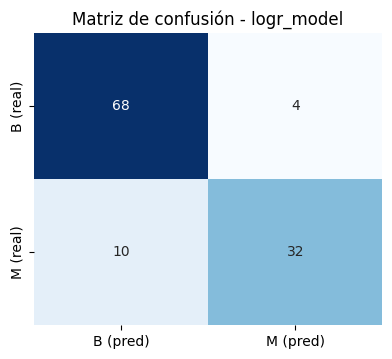

Verdaderos negativos (VN): 68 | Falsos positivos (FP): 4
Falsos negativos (FN): 10     | Verdaderos positivos (VP): 32


In [43]:
# Visualización de la matriz de confusión del modelo 1
cm1 = confusion_matrix(ytest, predictions, labels=['B','M'])
plt.figure(figsize=(4.5,3.8))
sns.heatmap(cm1, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['B (pred)','M (pred)'], yticklabels=['B (real)','M (real)'])
plt.title('Matriz de confusión - logr_model')
plt.show()

tn, fp, fn, tp = cm1.ravel()
print(f'Verdaderos negativos (VN): {tn} | Falsos positivos (FP): {fp}')
print(f'Falsos negativos (FN): {fn}     | Verdaderos positivos (VP): {tp}')

## **<font color="orange">INTERPRETE LOS RESULTADOS OBTENIDOS EN MATRIZ DE CONFUSION Y METRICAS</font>**

**Interpretación del modelo 1 (`logr_model`).**

* **Matriz de confusión** (filas = valor real, columnas = predicción, orden `['B','M']`): `[[68, 4], [10, 32]]`. Es decir, 68 **verdaderos negativos** (benignos bien clasificados), 4 **falsos positivos** (benignos marcados como malignos), 10 **falsos negativos** (malignos que el modelo no detectó) y 32 **verdaderos positivos** (malignos bien detectados). El conjunto de prueba tiene 114 observaciones (72 benignas y 42 malignas).
* **Recall ≈ 0.762:** el modelo detecta 32 de los 42 tumores malignos reales (≈ 76 %). Es la métrica más crítica en este problema, porque un falso negativo es un caso maligno sin detectar.
* **Precision ≈ 0.889:** de los 36 casos que el modelo clasificó como malignos, 32 realmente lo eran (≈ 89 %); los otros 4 son falsas alarmas.
* **Accuracy ≈ 0.877:** el modelo acierta en ≈ 88 % de todas las observaciones de prueba.

El modelo base tiene un desempeño aceptable pero mejorable: el *accuracy* es razonable, sin embargo deja pasar 10 de 42 casos malignos, que es justo el error más costoso. Las variables están en escalas muy distintas (por ejemplo `radius_mean` ≈ 7–28 frente a `smoothness_mean` ≈ 0.05–0.16) y varias tienen sesgo positivo, lo que dificulta el ajuste de los coeficientes de la regresión logística. Eso motiva el segundo modelo.

Para generar un modelo `logr_model2` con transformación y escalamiento:

6a) Modifica el transformador anterior para, además del borrado de las columnas correlacionadas, aplicar la raíz cuadrada a los predictores con sesgo (previamente almacenados en `skew_cols`) y escalamiento *MinMax* a los predictores con escala mayor a 1 (previamente almacenados en `scale_cols`) Como no todos los predictores serán eliminados o transformados, asegúrate de incluir el parámetro `remainder='passthrough'`

In [44]:
#EXPLIQUE CADA LINEA DE CODIGO

preprocessing2 = ColumnTransformer([
    # 'num0': borra (drop) las 18 columnas altamente correlacionadas
    ('num0','drop', columnas_a_eliminar),
    # 'num1': aplica la raíz cuadrada (np.sqrt, envuelta en FunctionTransformer) a las columnas con sesgo positivo (skew_cols)
    # para reducir la asimetría y el peso de los valores extremos
    ('num1',FunctionTransformer(np.sqrt),skew_cols),
    # 'num2': aplica escalamiento MinMax (deja los valores en [0,1]) a las columnas fuera de ese intervalo (scale_cols)
    ('num2',MinMaxScaler(),scale_cols)
  # remainder='passthrough': las columnas no mencionadas pasan sin cambios
  ],remainder='passthrough')

6b) Entrena el modelo `logr_model2` con regresión logística, aplicando previamente el transformador modificado. Evalúa el modelo en el conjunto de prueba con las mismas métricas.

In [45]:
#ESCRIBA CODIGO AQUI

# Pipeline: preprocesamiento modificado (borrado + raíz cuadrada + MinMax) seguido de regresión logística
logr_model2=make_pipeline(preprocessing2, LogisticRegression())

# Entrenamiento con el mismo conjunto de entrenamiento
logr_model2.fit(Xtrain,ytrain)

# Predicciones sobre el mismo conjunto de prueba
predictions2=logr_model2.predict(Xtest)

# Mismas métricas que en el modelo 1
print('matriz de confusion 2:\n',confusion_matrix(ytest,predictions2,labels=['B','M']))
print('recall    :\t',recall_score(ytest,predictions2,pos_label='M'))
print('precision :\t',precision_score(ytest,predictions2,pos_label='M'))
print('accurancy :\t',accuracy_score(ytest,predictions2))

matriz de confusion 2:
 [[72  0]
 [11 31]]
recall    :	 0.7380952380952381
precision :	 1.0
accurancy :	 0.9035087719298246


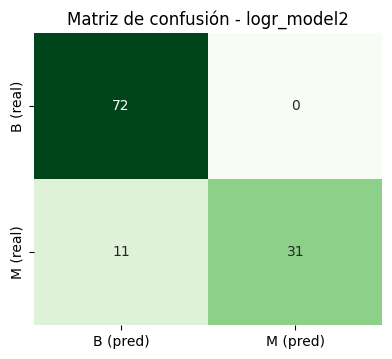

Verdaderos negativos (VN): 72 | Falsos positivos (FP): 0
Falsos negativos (FN): 11     | Verdaderos positivos (VP): 31


In [46]:
# Visualización de la matriz de confusión del modelo 2
cm2 = confusion_matrix(ytest, predictions2, labels=['B','M'])
plt.figure(figsize=(4.5,3.8))
sns.heatmap(cm2, annot=True, fmt='d', cmap='Greens', cbar=False,
            xticklabels=['B (pred)','M (pred)'], yticklabels=['B (real)','M (real)'])
plt.title('Matriz de confusión - logr_model2')
plt.show()

tn2, fp2, fn2, tp2 = cm2.ravel()
print(f'Verdaderos negativos (VN): {tn2} | Falsos positivos (FP): {fp2}')
print(f'Falsos negativos (FN): {fn2}     | Verdaderos positivos (VP): {tp2}')

In [47]:
# Tabla comparativa de ambos modelos en el conjunto de prueba
comparacion = pd.DataFrame({
    'Modelo': ['logr_model (baseline)', 'logr_model2 (sqrt + MinMax)'],
    'VN': [tn, tn2], 'FP': [fp, fp2], 'FN': [fn, fn2], 'VP': [tp, tp2],
    'Recall (M)': [recall_score(ytest,predictions,pos_label='M'), recall_score(ytest,predictions2,pos_label='M')],
    'Precision (M)': [precision_score(ytest,predictions,pos_label='M'), precision_score(ytest,predictions2,pos_label='M')],
    'Accuracy': [accuracy_score(ytest,predictions), accuracy_score(ytest,predictions2)]
}).set_index('Modelo')
comparacion.round(4)

,VN,FP,FN,VP,Recall (M),Precision (M),Accuracy
Modelo,,,,,,,
logr_model (baseline),68,4,10,32,0.7619,0.8889,0.8772
logr_model2 (sqrt + MinMax),72,0,11,31,0.7381,1.0000,0.9035


## **<font color="orange">INTERPRETE LOS RESULTADOS OBTENIDOS EN MATRIZ DE CONFUSION Y METRICAS</font>**

**Interpretación del modelo 2 (`logr_model2`).**

* **Matriz de confusión:** `[[72, 0], [11, 31]]`: 72 verdaderos negativos, **0 falsos positivos**, 11 falsos negativos y 31 verdaderos positivos.
* **Precision = 1.0:** todos los casos que el modelo marcó como malignos realmente lo eran (se eliminaron las 4 falsas alarmas del modelo 1).
* **Accuracy ≈ 0.904:** sube de ≈ 0.877 a ≈ 0.904 (103 aciertos de 114 frente a 100 del modelo 1).
* **Recall ≈ 0.738:** baja ligeramente respecto al modelo 1 (≈ 0.762), porque ahora se detectan 31 de los 42 malignos en lugar de 32 (un falso negativo más).

**Comparación.** La raíz cuadrada (reduce la asimetría y el efecto de valores extremos) y el escalamiento *MinMax* (deja las variables en una escala comparable) mejoraron el *accuracy* y, sobre todo, la *precision*: el modelo es más "cuidadoso" al etiquetar un caso como maligno. Sin embargo, no mejoró el *recall*, que es la métrica más importante cuando el costo de un falso negativo es alto: sigue dejando pasar 11 de 42 casos malignos. En conclusión, el preprocesamiento ayuda, pero para priorizar la detección de casos malignos habría que probar otras opciones (por ejemplo, ajustar el umbral de decisión, usar `class_weight='balanced'` o aumentar `C`/`max_iter` en la regresión logística).

## **<font color="orange">CONCLUSIÓN DE LA PRÁCTICA</font>**

En esta práctica se construyó un clasificador de **regresión logística** para predecir si un diagnóstico es benigno (`B`) o maligno (`M`) a partir de 30 características numéricas de núcleos celulares.

1. **Exploración (EDA).** El conjunto no tiene valores faltantes y las clases están moderadamente desbalanceadas (más `B` que `M`), por lo que, además del *accuracy*, se evaluaron *recall* y *precision* de la clase maligna.
2. **Multicolinealidad.** El mapa de calor y el `pairplot` mostraron correlaciones muy altas entre las versiones `_mean` y `_worst` de cada variable, y entre `radius`, `perimeter` y `area`, así como entre `compactness`, `concavity` y `concave points`. Se eliminaron 18 variables redundantes (las 10 `_worst` y 8 variables `_mean`/`_se`), dejando 12 predictores.
3. **Transformación y escalamiento.** Se detectaron variables con sesgo positivo (`skew() > 1`) y variables fuera del intervalo [0, 1], a las que se les aplicó raíz cuadrada y escalamiento *MinMax* respectivamente dentro de un `ColumnTransformer`.
4. **Modelos.** El modelo base (`logr_model`) y el modelo con transformación y escalamiento (`logr_model2`) se evaluaron con la misma partición 80:20 (`random_state=1`), de modo que la comparación es justa. El modelo con transformación y escalamiento mejoró el *accuracy* (≈ 0.877 → ≈ 0.904) y la *precision* (≈ 0.889 → 1.0, sin falsos positivos), pero el *recall* bajó ligeramente (≈ 0.762 → ≈ 0.738), es decir, sigue pasando por alto algunos casos malignos.
5. **Aprendizaje.** Eliminar variables altamente correlacionadas reduce la redundancia sin perder capacidad predictiva, y encadenar el preprocesamiento y el modelo en un `Pipeline` evita fugas de información (el escalador se ajusta solo con el conjunto de entrenamiento). En un problema médico como este, la métrica prioritaria es el **recall** de la clase maligna, ya que un falso negativo es más costoso que un falso positivo.